In [27]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load
%pip install -U kagglehub
%pip install -U pandas
%pip install tensorflow
%pip install seaborn
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import tensorflow as tf
from tensorflow.keras.metrics import RootMeanSquaredError
from tensorflow.keras.optimizers import Adam
import seaborn as sns
from tensorflow.keras.layers import Normalization, Dense, InputLayer
import matplotlib.pyplot as plt
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [28]:
path = kagglehub.dataset_download(
    "mayankpatel14/second-hand-used-cars-data-set-linear-regression"
)
data = pd.read_csv(os.path.join(path, "train.csv"))


In [29]:
data.head()

,v.id,on road old,on road now,years,km,rating,condition,economy,top speed,hp,torque,current price
0,1,535651,798186,3,78945,1,2,14,177,73,123,351318.0
1,2,591911,861056,6,117220,5,9,9,148,74,95,285001.5
2,3,686990,770762,2,132538,2,8,15,181,53,97,215386.0
3,4,573999,722381,4,101065,4,3,11,197,54,116,244295.5
4,5,691388,811335,6,61559,3,9,12,160,53,105,531114.5


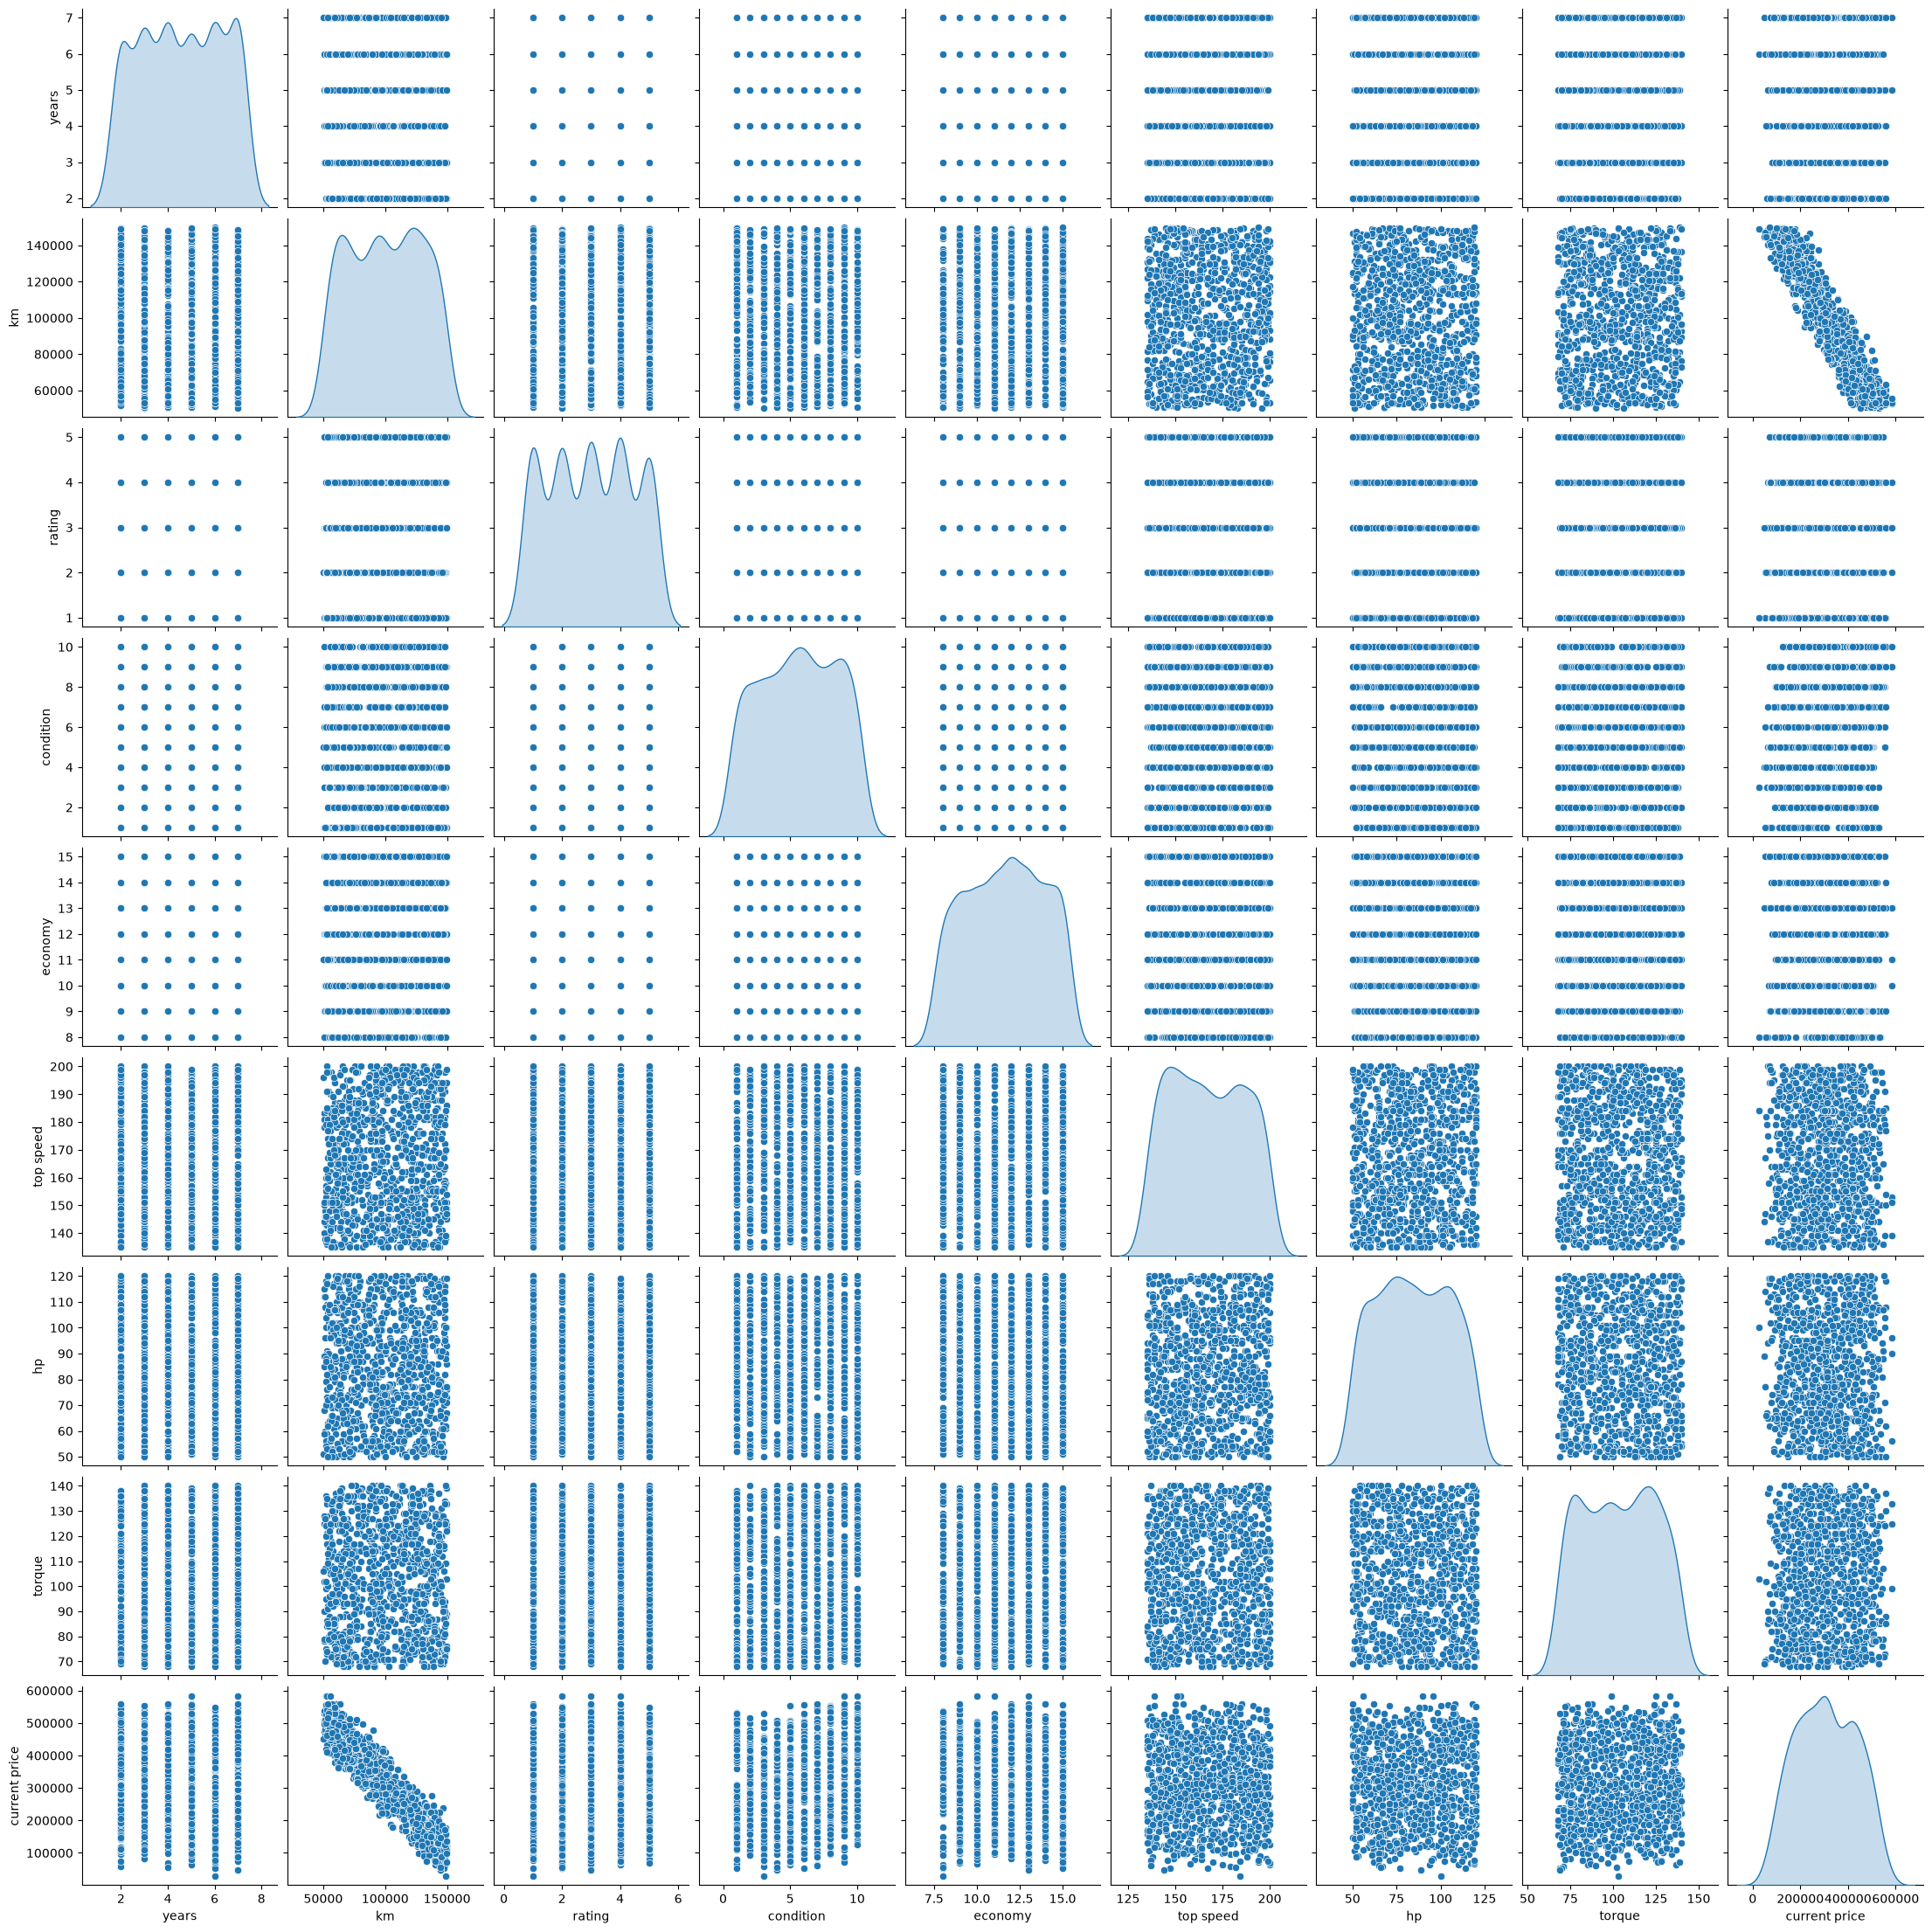

In [30]:
sns.pairplot(data[['years', 'km', 'rating', 'condition', 'economy', 'top speed', 'hp', 'torque', 'current price']], diag_kind='kde')

In [31]:
shuffled_data = tf.random.shuffle(data)

In [32]:
shuffled_data[: 5]

<tf.Tensor: shape=(5, 12), dtype=float64, numpy=
array([[3.990000e+02, 6.434140e+05, 8.352630e+05, 6.000000e+00,
        1.212640e+05, 3.000000e+00, 2.000000e+00, 9.000000e+00,
        1.980000e+02, 1.130000e+02, 8.600000e+01, 2.507710e+05],
       [3.090000e+02, 5.717280e+05, 7.076660e+05, 4.000000e+00,
        7.867300e+04, 4.000000e+00, 7.000000e+00, 1.200000e+01,
        1.790000e+02, 7.700000e+01, 9.400000e+01, 3.336555e+05],
       [5.690000e+02, 6.577380e+05, 8.568070e+05, 7.000000e+00,
        7.287200e+04, 4.000000e+00, 8.000000e+00, 1.400000e+01,
        1.740000e+02, 6.100000e+01, 1.400000e+02, 4.745625e+05],
       [8.870000e+02, 5.699820e+05, 8.382040e+05, 4.000000e+00,
        1.025570e+05, 3.000000e+00, 6.000000e+00, 1.300000e+01,
        1.920000e+02, 6.300000e+01, 1.010000e+02, 2.976250e+05],
       [4.390000e+02, 5.057280e+05, 7.497730e+05, 5.000000e+00,
        1.005340e+05, 1.000000e+00, 9.000000e+00, 1.500000e+01,
        1.370000e+02, 7.200000e+01, 1.190000e+02, 2

In [33]:
X = shuffled_data[:,3:-1]
print(X[:5])
y = shuffled_data[:,-1]
print(y[:5].shape)
y = tf.expand_dims(y, axis = -1)
print(y[:5])

tf.Tensor(
[[6.00000e+00 1.21264e+05 3.00000e+00 2.00000e+00 9.00000e+00 1.98000e+02
  1.13000e+02 8.60000e+01]
 [4.00000e+00 7.86730e+04 4.00000e+00 7.00000e+00 1.20000e+01 1.79000e+02
  7.70000e+01 9.40000e+01]
 [7.00000e+00 7.28720e+04 4.00000e+00 8.00000e+00 1.40000e+01 1.74000e+02
  6.10000e+01 1.40000e+02]
 [4.00000e+00 1.02557e+05 3.00000e+00 6.00000e+00 1.30000e+01 1.92000e+02
  6.30000e+01 1.01000e+02]
 [5.00000e+00 1.00534e+05 1.00000e+00 9.00000e+00 1.50000e+01 1.37000e+02
  7.20000e+01 1.19000e+02]], shape=(5, 8), dtype=float64)
(5,)
tf.Tensor(
[[250771. ]
 [333655.5]
 [474562.5]
 [297625. ]
 [253853.5]], shape=(5, 1), dtype=float64)


In [34]:
print(X.shape, y.shape)

(1000, 8) (1000, 1)


normalization formula is $\frac{x-mean}{\sqrt(var)}$


In [35]:
TRAIN_RATIO = 0.8
VAL_RATIO = 0.1
TEST_RATIO = 0.1
DATASET_SIZE = len(X)
print(DATASET_SIZE)

1000


In [36]:
X_TRAIN = X[:int(DATASET_SIZE * TRAIN_RATIO)]
y_TRAIN = y[:int(DATASET_SIZE * TRAIN_RATIO)]
print(X_TRAIN.shape, y_TRAIN.shape)

(800, 8) (800, 1)


In [37]:
#colums -> axis = -1
normalizer = Normalization(axis = -1)
normalizer.adapt(X_TRAIN)

normalizer_y = Normalization(axis = -1)
normalizer_y.adapt(y_TRAIN)


In [38]:
X_VAL = X[int(DATASET_SIZE * TRAIN_RATIO):int(DATASET_SIZE * (TRAIN_RATIO + VAL_RATIO))]
y_VAL = y[int(DATASET_SIZE * TRAIN_RATIO):int(DATASET_SIZE * (TRAIN_RATIO + VAL_RATIO))]
print(X_VAL.shape, y_VAL.shape)

(100, 8) (100, 1)


In [39]:
X_TEST = X[int(DATASET_SIZE * (TRAIN_RATIO + VAL_RATIO)):]
y_TEST = y[int(DATASET_SIZE * (TRAIN_RATIO  + VAL_RATIO)):]
print(X_TEST.shape, y_TEST.shape)

(100, 8) (100, 1)


In [40]:
model = tf.keras.Sequential([
    InputLayer(shape=(8,)),
    normalizer,
    Dense(1)
], name='first-sequential-api')
model.summary()


Model: "first-sequential-api"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_2 (Normalization) │ (None, 8)              │            17 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26 (108.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 17 (72.00 B)

In [41]:
model.compile(optimizer=Adam(learning_rate = 0.001), loss= tf.keras.losses.Huber(), metrics = [RootMeanSquaredError()])

In [42]:
history = model.fit(X_TRAIN,normalizer_y(y_TRAIN),validation_data=(X_VAL,normalizer_y(y_VAL)),epochs=100, verbose = 1)

Epoch 1/100


25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.8088 - root_mean_squared_error: 1.5111 - val_loss: 0.7605 - val_root_mean_squared_error: 1.4437
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7664 - root_mean_squared_error: 1.4557 - val_loss: 0.7164 - val_root_mean_squared_error: 1.3874
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7245 - root_mean_squared_error: 1.4002 - val_loss: 0.6744 - val_root_mean_squared_error: 1.3330
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6836 - root_mean_squared_error: 1.3458 - val_loss: 0.6334 - val_root_mean_squared_error: 1.2795
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6435 - root_mean_squared_error: 1.2912 - val_loss: 0.5943 - val_root_mean_squared_error: 1.2280
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6048 - root_mean_squared_error: 1.2391 - val_loss: 0.5557 - val_root_mean_squared_error: 1.1766
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5667 - ro

In [43]:
loss = history.history['val_loss']


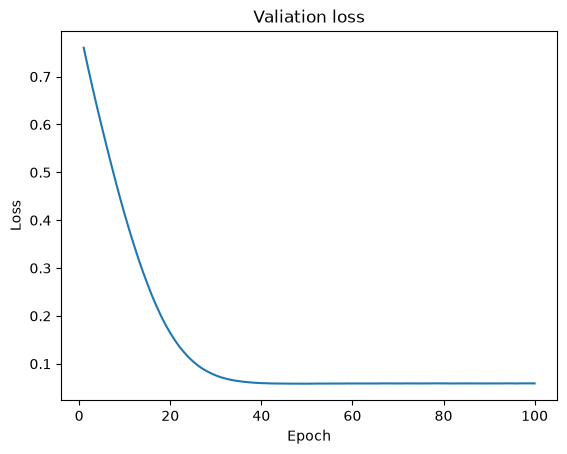

In [44]:
sns.lineplot(x=range(1, len(loss) + 1), y=loss)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Valiation loss")
plt.show()

In [45]:
root_mean_squared =  history.history['val_root_mean_squared_error']

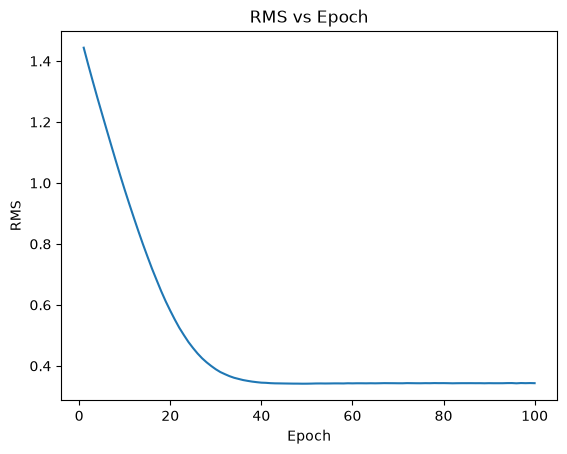

In [46]:
sns.lineplot(x=range(1, len(root_mean_squared) + 1), y=root_mean_squared)
plt.xlabel("Epoch")
plt.ylabel("RMS")
plt.title("RMS vs Epoch")
plt.show()

In [47]:
model.evaluate(X_VAL,normalizer_y(y_VAL))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0589 - root_mean_squared_error: 0.3433 


[0.0589270293712616, 0.3432987928390503]

In [48]:
y_pred_norm = model.predict(X_TEST)

y_pred = (
    y_pred_norm * tf.sqrt(normalizer_y.variance)
    + normalizer_y.mean
).numpy()[:, 0]
print(y_pred.shape) 

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
(100,)


In [49]:
print(y_pred)

[278448.4   125366.47   91979.86  348763.5   504820.5   481101.94
 327328.84  179350.    223555.4   341331.88  120959.3   345843.22
 396082.    294021.38  231149.84  210031.34  128228.56  263772.12
 335831.22  508533.94  363371.47  357557.16  520225.97  311500.16
 503168.88  375196.75  428818.16  465005.72  232247.28  165253.69
 443747.3   150410.67  204262.62  452671.44  500334.    408385.44
 150449.75  154421.27  465040.06  284340.7   377702.88  118528.5
 336193.66  374940.3   240338.39  430297.6   190781.4   219756.19
 474755.6   427978.8   222872.8   409640.8   497285.62  326858.28
 346879.8   356650.53  351605.5   136539.2   268944.34  380347.47
 446347.25  322277.6   338958.84  248941.06  489220.47  199806.78
 129521.33  385062.1   205919.84  204976.8   248620.    254562.52
 401796.25  157099.53  276015.8   224902.78  349579.9   227973.72
 108893.016 105425.984 200201.06  271568.88  416285.1   305841.94
 489516.    418363.9   324378.7   251324.36  451318.88  274444.06
 126537.31 

In [50]:
y_true = y_TEST[:,0]

In [51]:
print(y_true)

tf.Tensor(
[271010.5 169471.   28226.5 351201.5 460780.  547746.  341328.  207480.5
 229982.  302011.5 166283.  324373.  318858.  239746.  237954.  207352.5
  94467.5 249603.  399055.5 528634.  383570.5 332812.  584116.5 291031.5
 458833.5 312164.5 528770.  491123.  221972.5 200794.5 452931.  110883.5
 156513.  377108.5 479896.  425960.  153375.5 198511.5 530759.  311973.
 354900.  179077.  340961.5 378071.5 283435.5 365136.5 254581.  265194.
 512492.  387089.  265799.5 433615.5 486308.5 380231.  432159.5 337917.
 366732.  128632.5 234835.5 382794.5 498418.  301081.5 308643.5 287093.5
 547069.  158951.5  77277.  459833.5 184092.5 257565.5 258268.5 285001.5
 330908.5 110359.5 276430.  268314.  327994.  274453.5 104215.  122567.5
 188131.5 310987.  510929.  282496.5 462715.5 426796.5 410403.5 311773.5
 443735.5 231291.5 177933.5 465338.5 379566.  368522.5 499121.  553855.
 414035.  304445.  390305.5 331263.5], shape=(100,), dtype=float64)


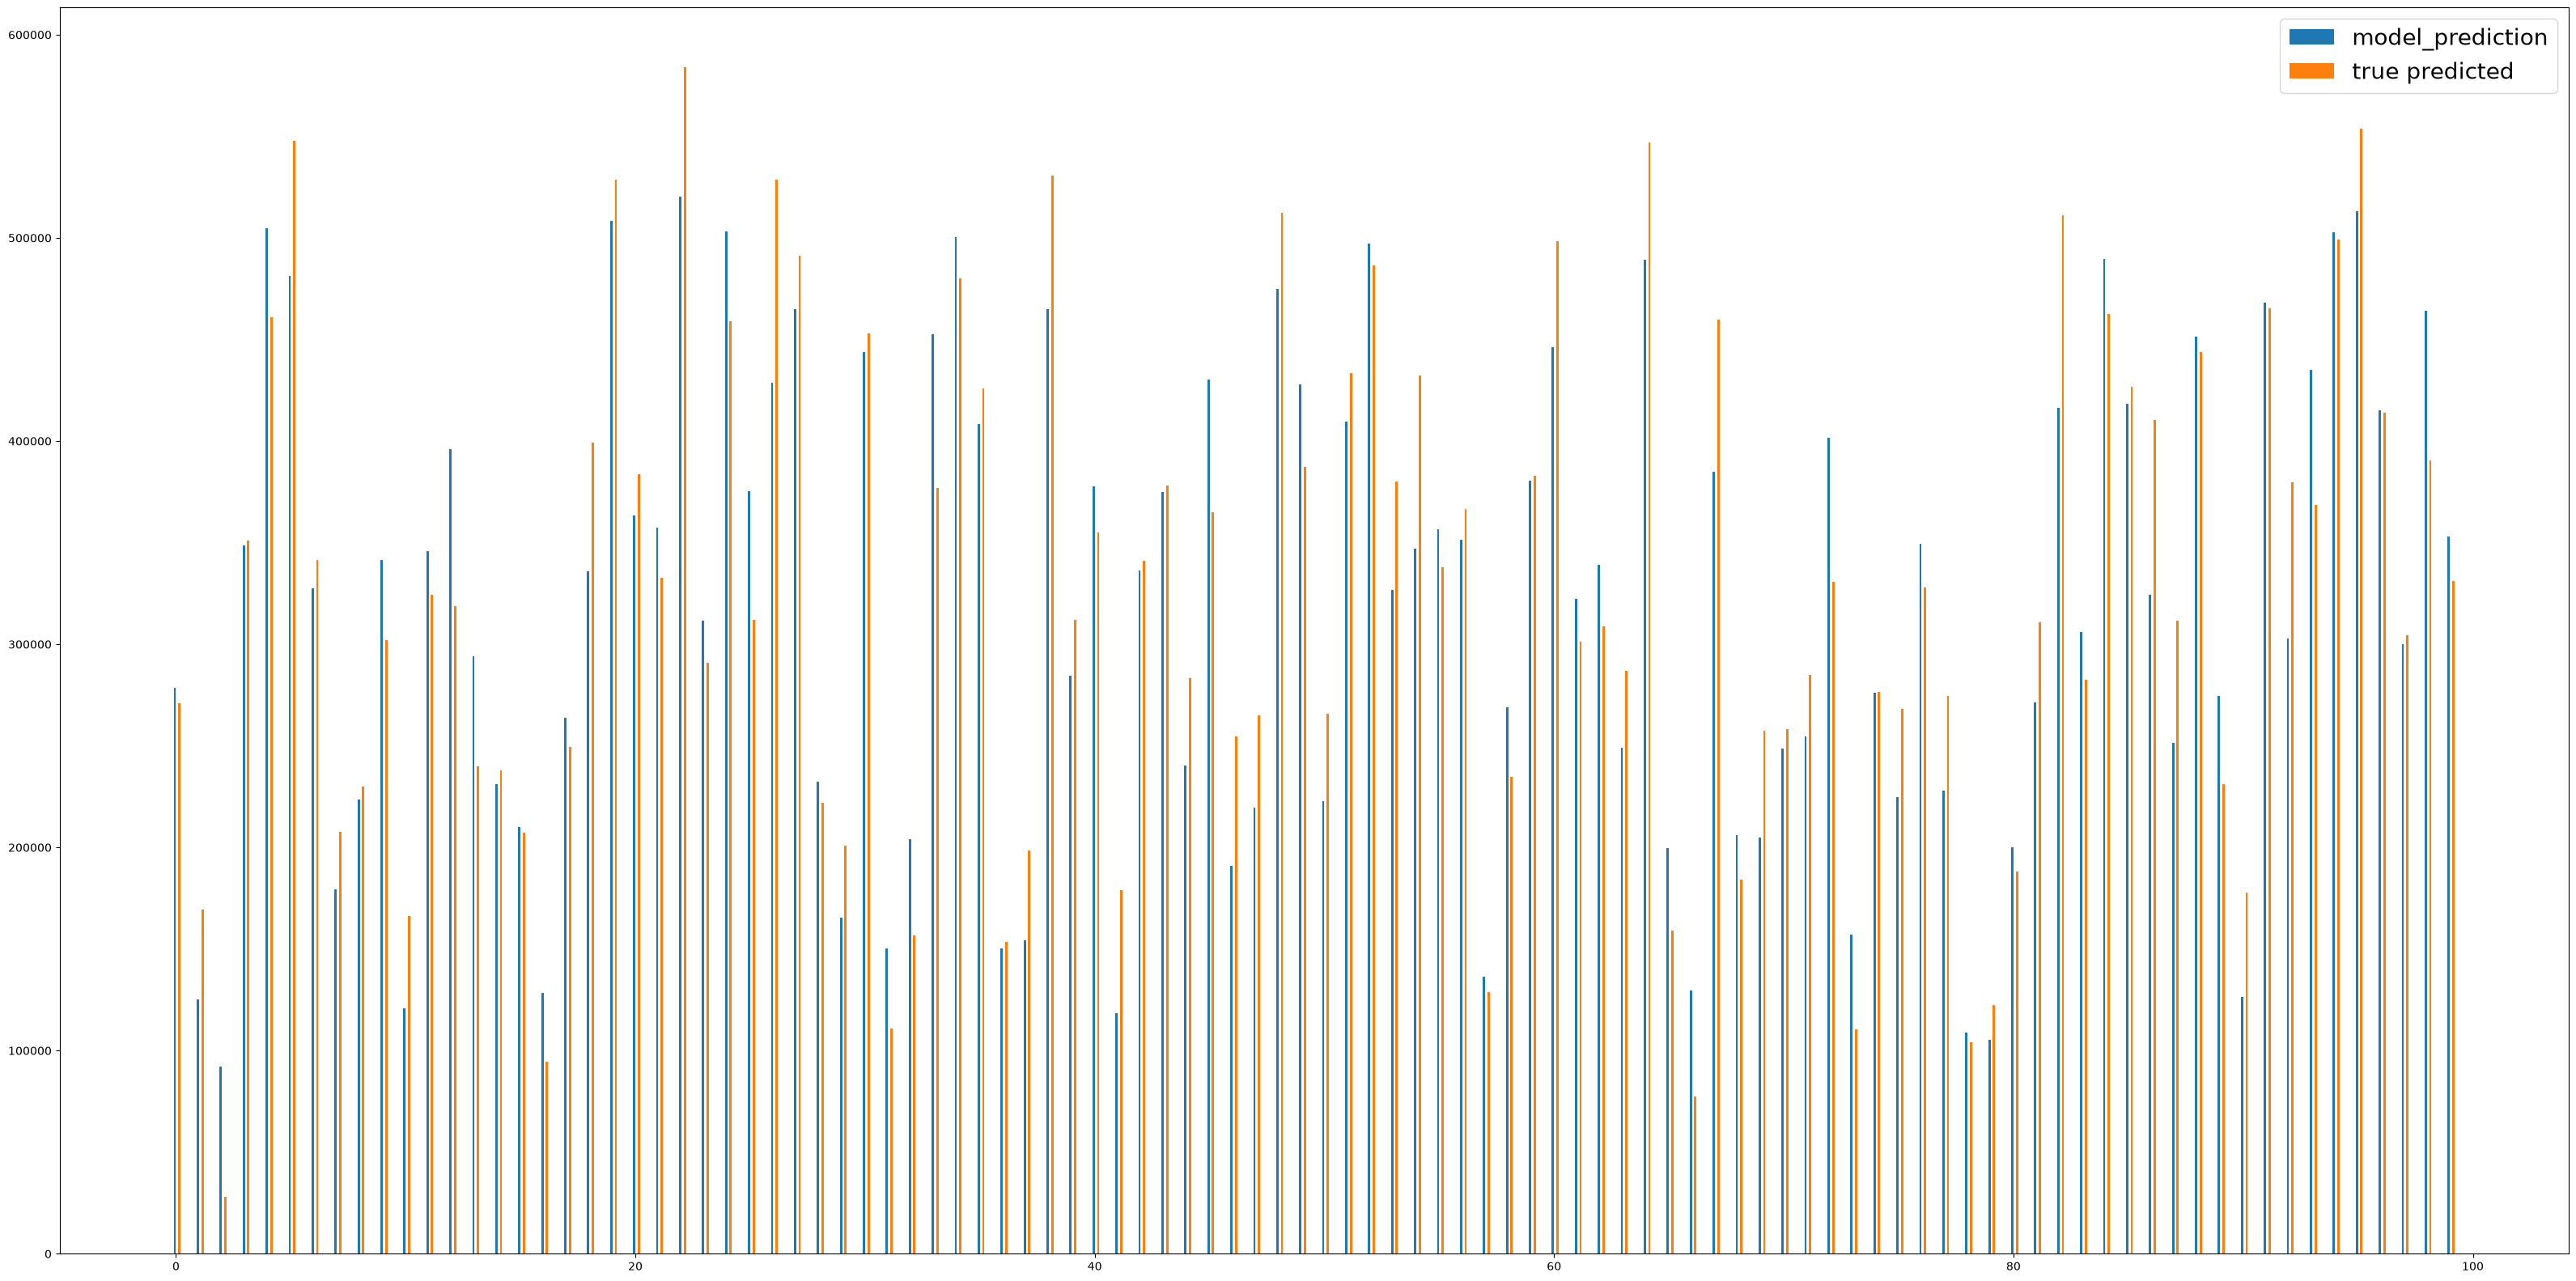

In [52]:
plt.figure(figsize = [40, 20])
width = 0.1
x = tf.range(100).numpy()
plt.bar(x - width/2, y_pred, width, label='model_prediction')
plt.bar(x + width/2 + width, y_true, width, label='true predicted')
plt.legend(fontsize=20)
plt.savefig('my_plot.png', dpi=300, bbox_inches='tight')
